# Voice Protection Model — streaming adversarial perturbations against voice cloning
**Dennis — MSc Data Science & Analytics, Strathmore University.** Research prototype implementing Chapter 3 (Research Methodology) of the proposal at CPU scale.

Pipeline (CRISP-DM, §3.1): **data → cleaning → EDA → preprocessing (10 ms blocks / look-ahead) → training of the causal streaming generator G-M (B6) and baselines → evaluation under the threat model (Table 3.1) → ONNX export → INT8 optimisation & latency benchmark.**

> All numbers in this notebook are computed from real runs on this machine (8 vCPU, no GPU, ~15 GB RAM). Long jobs (generator training, full evaluation) were run with the scripts in `scripts/` and their outputs are loaded here; set `RERUN=True` to recompute. **Everything scaled down from the proposal is listed in §11.**

In [1]:
import os, sys, json, glob, warnings; warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, 'src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, yaml, soundfile as sf
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
cfg = yaml.safe_load(open('config.yaml')); RERUN = False
print('torch', torch.__version__, '| threads', torch.get_num_threads(), '| CUDA', torch.cuda.is_available())

torch 2.14.1+cpu | threads 8 | CUDA False


## 1. Datasets — sources, licences, rationale
| Corpus | Licence | Access | Used for | Why |
|---|---|---|---|---|
| **LibriSpeech dev-clean** (OpenSLR SLR12) | CC BY 4.0 | direct download, no login | generator **training** (30 speakers) + **validation**/λ selection (10 speakers) | Proposal's training/clone corpus (Table 3.2); cloning is restricted to LibriSpeech. *train-clean-100 (251 spk, 6.3 GB) swapped for dev-clean for CPU budget.* |
| **LibriSpeech test-clean** | CC BY 4.0 | direct | **test** (40 speakers, disjoint) | Exactly the proposal's 40 English test speakers |
| **FLEURS Swahili – Kenya (`sw_ke`)** (Google) | CC BY 4.0 | Hugging Face, no login | Kenyan-locale Swahili **utility & embedding analysis only** (no cloning) | Stand-in for Common Voice Swahili / NBVS (Kenyan Swahili) |

Not used: **Common Voice** (now gated behind Mozilla Data Collective sign-in/terms), **VoxCeleb** (requires request form), **AfriSpeech-200** (CC BY-NC-SA, licence for this use 'to be confirmed' in the proposal), **ALFFA** (ASR sanity checks only in the proposal). NBVS, the real Safaricom/Airtel channel set and the lecture-hall PA set are new data to be collected and do not exist yet. Re-download with `scripts/download_data.sh`.

## 2. Cleaning (§3.3.5)
mono 16 kHz → energy-VAD trim (top_db 30) → drop corrupt / clipped (>0.1 % samples at full scale) / <2 s → cap 20 s → **−26 LUFS** (so ε means the same everywhere) → speaker-disjoint, gender-balanced splits. Run by `scripts/prepare_data.py` (parallel, 8 workers).

In [2]:
if RERUN: os.system('PYTHONPATH=src python scripts/prepare_data.py')
m = pd.read_csv('data/manifests/all.csv'); ex = pd.read_csv('data/manifests/excluded.csv')
from vpm.eda import summary_table, plot_overview, plot_spectrograms
print('kept', len(m), '| excluded', len(ex)); print(ex.groupby(['corpus','status']).size())
# speaker-disjointness check
sp = m[m.corpus=='librispeech'].groupby('speaker').split.nunique(); assert (sp==1).all(); print('speaker-disjoint splits: OK')
summary_table(m)

kept 5600 | excluded 421
corpus        status   
fleurs_sw_ke  too_short      2
librispeech   clipping       3
              too_short    416
dtype: int64
speaker-disjoint splits: OK


utterances  speakers  hours  mean_dur_s  median_snr_est_db  female_share
corpus       split                                                                            
fleurs_sw_ke sw_dev          211         1   0.76       12.90              26.46          0.28
             sw_test         485         1   1.82       13.52              25.58          0.28
librispeech  test           2427        40   4.82        7.15              31.08          0.52
             train          1875        30   3.53        6.78              31.99          0.51
             val             602        10   1.19        7.13              31.61          0.51

## 3. Exploratory data analysis

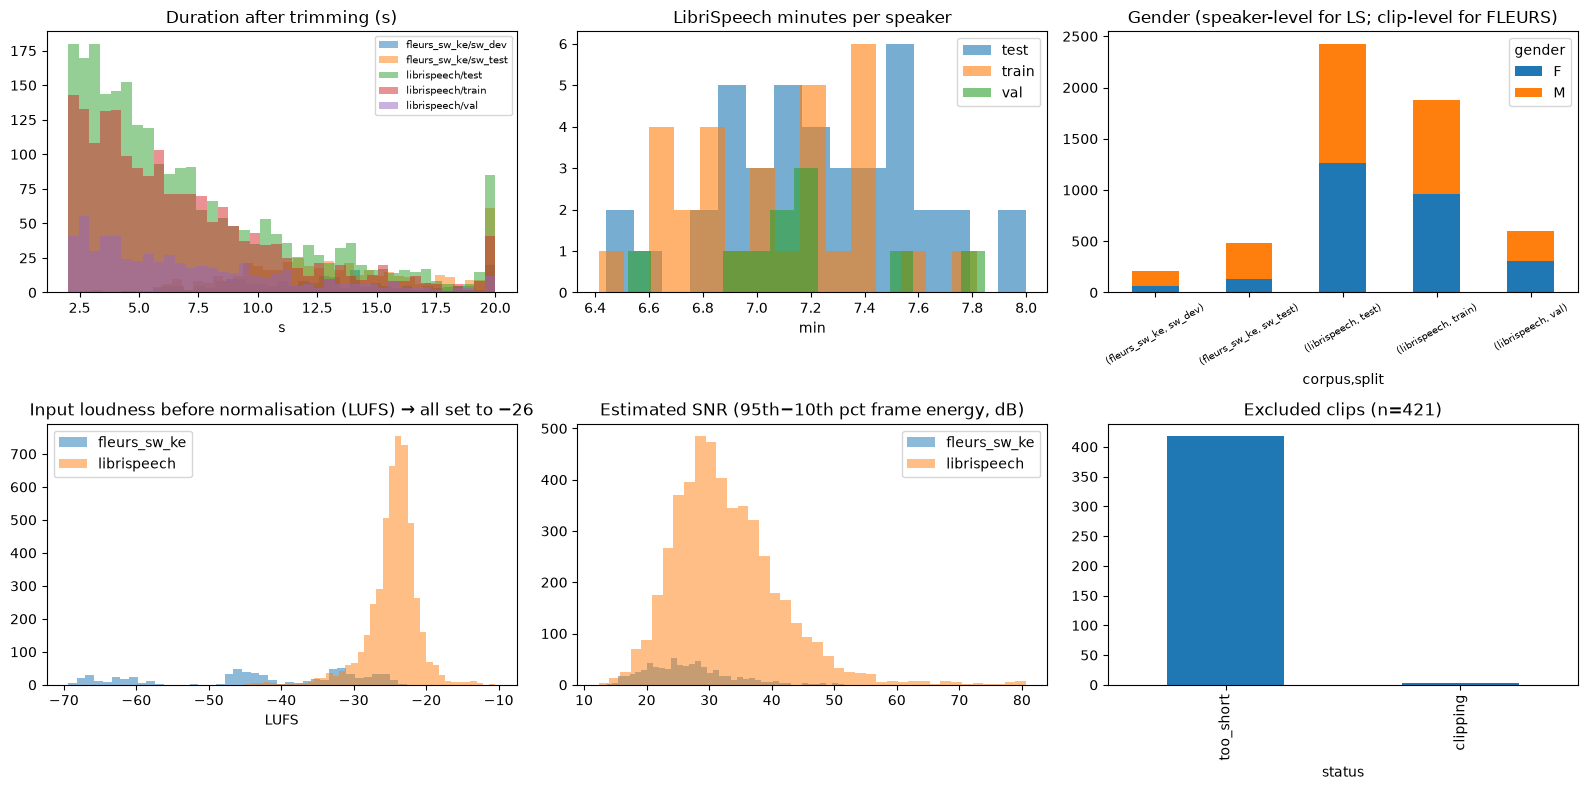

In [3]:
fig = plot_overview(m, ex, 'plots/eda_overview.png'); plt.show()

In [4]:
ls = m[m.corpus=='librispeech']
print(ls.groupby(['split','gender']).speaker.nunique().unstack())
print(m.groupby('corpus')[['dur','raw_dur','lufs_in','snr_est']].describe().T.round(2))

gender   F   M
split         
test    20  20
train   15  15
val      5   5
corpus         fleurs_sw_ke  librispeech
dur     count        696.00      4904.00
        mean          13.34         7.01
        std            4.05         4.44
        min            2.53         2.02
        25%           10.24         3.65
        50%           12.97         5.70
        75%           16.36         9.12
        max           20.00        20.00
raw_dur count        696.00      4904.00
        mean          14.08         7.72
        std            4.53         4.90
        min            4.56         2.02
        25%           10.86         4.18
        50%           13.44         6.30
        75%           16.68         9.79
        max           42.42        34.96
lufs_in count        696.00      4904.00
        mean         -42.41       -24.51
        std           13.43         3.45
        min          -69.42       -45.01
        25%          -47.26       -25.81
        50%          -4

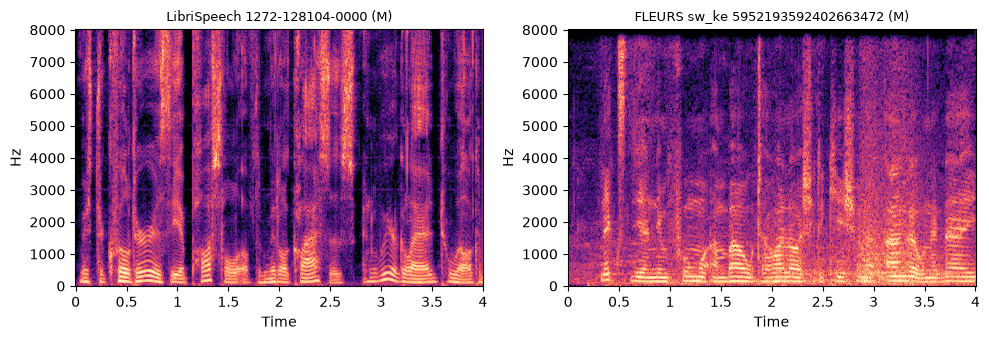

In [5]:
ex1 = m[(m.split=='train')].iloc[0]; ex2 = m[m.split=='sw_test'].iloc[0]
fig = plot_spectrograms([ex1.clean_path, ex2.clean_path], [f'LibriSpeech {ex1.utt_id} ({ex1.gender})', f'FLEURS sw_ke {ex2.utt_id} ({ex2.gender})'], 'plots/eda_spectrograms.png'); plt.show()

## 4. Preprocessing for the streaming design (§3.6.2)
16 kHz audio in **10 ms hops (160 samples)**; each block's **20 ms analysis window ends at the current block** (previous + current block), so windowing adds no look-ahead. Per-block features = learned projection of the raw 320-sample window + **40-band log-mel** (DFT implemented as a matmul so it exports to ONNX/INT8). Look-ahead L is a fixed output delay: G-M uses **L = 1 block = 10 ms** (algorithmic latency 20 ms), G-S uses L = 0 (10 ms).

In [6]:
from vpm.generator import G_S, G_M, Generator, StreamingGenerator, stream_process
x = torch.tensor(sf.read(ex1.clean_path, dtype='float32')[0][:16000]); fr = Generator.frames(x[None])
print('waveform', tuple(x.shape), '→ blocks/windows', tuple(fr.shape), '(T blocks × 320-sample window)')
for g in (G_S(), G_M()):
    print(f"{'G-S' if g.L==0 else 'G-M'}: params={g.n_params():,}  ~MAC/s={g.macs_per_second()/1e6:.1f} M  look-ahead={g.L*10} ms  algorithmic latency={10+10*g.L} ms")
# unit test (§3.6.2): streaming == offline
g = G_M().eval(); xx = torch.randn(1, 160*80)*0.05
with torch.no_grad(): off = g(xx)[0]
print('max |offline − streaming| =', (off - stream_process(StreamingGenerator(g).eval(), xx[0])).abs().max().item())

waveform (16000,) → blocks/windows (1, 100, 320) (T blocks × 320-sample window)
G-S: params=79,840  ~MAC/s=9.6 M  look-ahead=0 ms  algorithmic latency=10 ms
G-M: params=286,144  ~MAC/s=29.6 M  look-ahead=10 ms  algorithmic latency=20 ms


max |offline − streaming| = 5.9371814131736755e-09


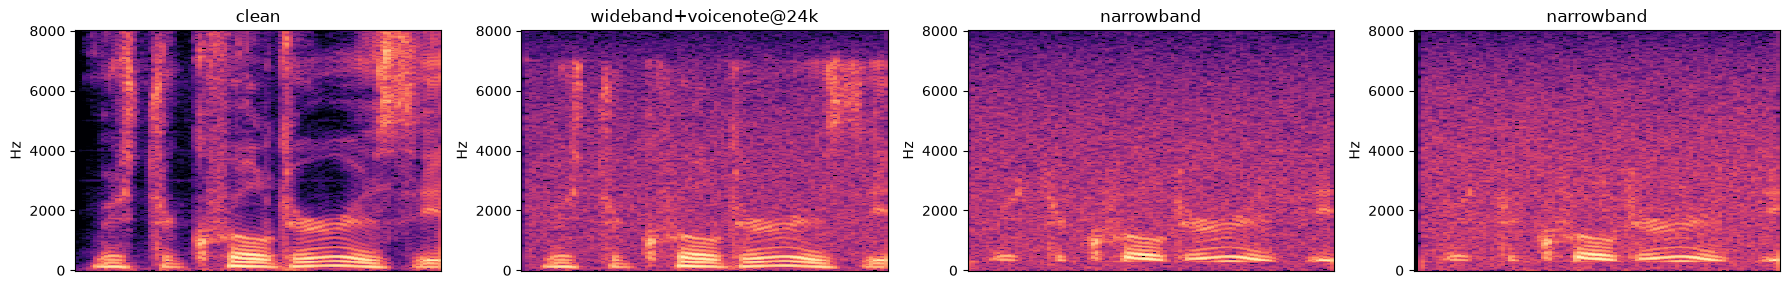

In [7]:
import random, librosa, librosa.display
from vpm import channels as ch
xc = x[None]; ex = [('clean', xc)] + [(d, y) for y, d in (ch.sample_ke(xc, xc, random.Random(s)) for s in (1, 4, 7))]
fig, ax = plt.subplots(1, 4, figsize=(18, 3))
for a, (name, y) in zip(ax, ex):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y[0].detach().numpy(), n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(S, sr=16000, hop_length=160, ax=a, y_axis='hz'); a.set_title(name)
plt.tight_layout(); plt.savefig('plots/channel_examples.png', dpi=100); plt.show()

## 5. Training (Eq. 11; §3.6.4)
Objective: \(\mathbb{E}_x\mathbb{E}_{t\sim T_{KE}}\cos(E(t(x+\delta_\theta)),E(x)) + \lambda(\mathcal L_{stft}+\gamma\mathcal L_{mask})\), seen encoder **ECAPA-TDNN** (SpeechBrain, VoxCeleb), ε = 0.008 (−42 dBFS, mid-grid), AdamW 3e-4 cosine, grad-clip 1, curriculum (clean+device → codecs → full incl. PA/re-recording & chains), mode switch (mobile / PA-live / unknown). Real Opus via ffmpeg with identity-STE BPDA; AMR replaced by a narrowband (8 kHz, 300–3400 Hz, G.711 µ-law) proxy.

Runs (`python -m vpm.train ...`): **B6 G-M T_KE λ=0.1** (main), G-M T_KE λ=1 (λ-grid point, stopped at 250 steps: no protection), **B5 G-M T_gen λ=0.1** (generic channel baseline for H2), **G-S T_KE λ=0.1** (0 ms look-ahead, A7/A8).

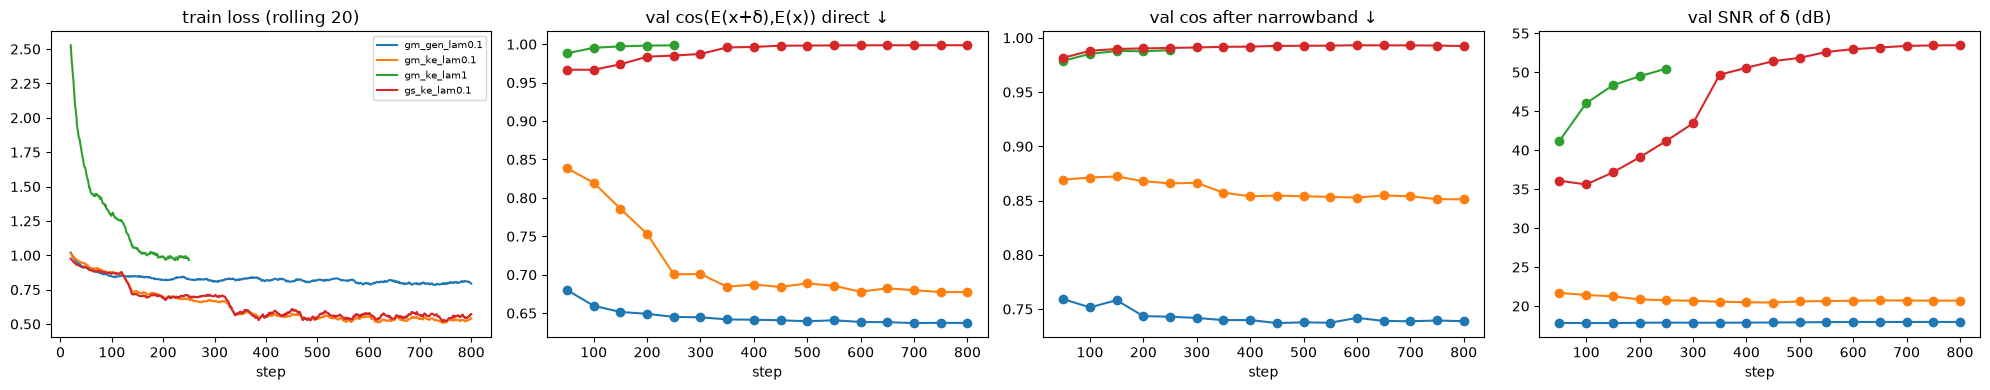

,step,val_cos,val_cos_nb,val_perc,val_snr
gm_gen_lam0.1,800.0,0.637291,0.738785,1.927714,17.960417
gm_ke_lam0.1,800.0,0.677437,0.851152,0.955741,20.693129
gm_ke_lam1,250.0,0.998537,0.988575,0.297999,50.476048
gs_ke_lam0.1,800.0,0.998700,0.992425,0.098857,53.468906


In [8]:
runs = {p.split('/')[1]: pd.read_csv(p) for p in sorted(glob.glob('models/*/log.csv'))}
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for k, d in runs.items():
    v = d.dropna(subset=['val_cos'])
    ax[0].plot(d.step, d.loss.rolling(20).mean(), label=k); ax[1].plot(v.step, v.val_cos, 'o-', label=k)
    ax[2].plot(v.step, v.val_cos_nb, 'o-', label=k); ax[3].plot(v.step, v.val_snr, 'o-', label=k)
for a, t in zip(ax, ['train loss (rolling 20)', 'val cos(E(x+δ),E(x)) direct ↓', 'val cos after narrowband ↓', 'val SNR of δ (dB)']): a.set_title(t); a.set_xlabel('step')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('plots/learning_curves.png', dpi=100); plt.show()
pd.DataFrame({k: d.dropna(subset=['val_cos']).iloc[-1][['step','val_cos','val_cos_nb','val_perc','val_snr']] for k, d in runs.items()}).T

## 6. Evaluation under the threat model (Table 3.1, scaled down)
`scripts/run_eval.py`: 40 LibriSpeech test speakers × 2 references (4–10 s) each, enrolment = 3 genuine utterances from other chapters. **No cloner is run** (see §11): the outcome is whether a verifier accepts the *protected reference itself* as the victim — the identity signal a cloner would copy. Thresholds τ_v at the clean EER point. Seen verifier: ECAPA. **Held-out (black-box transfer): WavLM-Base+ SV and Resemblyzer (GE2E).**

In [9]:
from vpm.report import thresholds, acceptance, ar_table, rho, h5
sc = pd.concat([pd.read_csv(f) for f in ['results/eval_scores.csv', 'results/eval_scores_e2.csv'] if os.path.exists(f)], ignore_index=True); q = pd.read_csv('results/eval_quality.csv')
thr = thresholds(sc); display(thr)
M = acceptance(sc, thr); T = ar_table(M); T.to_csv('results/ar_table.csv', index=False)
print('quality of protected references (direct, before any channel):')
Q = q.groupby('protection')[['snr_db','pesq_wb','stoi','linf']].agg(['mean','median']).round(3); Q.to_csv('results/quality_table.csv'); Q

,tau,clean_EER,n_genuine,n_impostor
ECAPA(seen),0.479331,0.000855,30.0,1170.0
Resemblyzer(held-out),0.817679,0.001709,30.0,1170.0
WavLM-SV(held-out),0.899600,0.066667,30.0,1170.0


quality of protected references (direct, before any channel):


snr_db          pesq_wb          stoi          linf       
                       mean   median    mean median   mean median   mean median
protection                                                                     
B0_unprotected      143.921  143.956   4.644  4.644  1.000  1.000  0.000  0.000
B1_gaussian          22.165   22.248   1.831  1.732  0.969  0.981  0.008  0.008
B4_teacher_PGD-EOT   20.231   20.288   1.746  1.697  0.931  0.941  0.008  0.008
B5_GM_generic        18.172   18.251   1.565  1.517  0.959  0.969  0.008  0.008
B6_GM_KE             20.867   20.955   2.007  2.003  0.974  0.977  0.008  0.008
B6_GM_KE_INT8(ORT)   20.864   20.953   2.006  2.003  0.974  0.977  0.008  0.008
GS_KE(0ms)           55.635   56.583   4.601  4.606  1.000  1.000  0.001  0.001

In [10]:
piv = T.pivot_table(index=['condition','channel'], columns=['verifier','protection'], values='AR_prot').round(2)
piv.to_csv('results/AR_pivot.csv'); piv

verifier                                       ECAPA(seen)                                                                                     Resemblyzer(held-out)                                 \
protection                                  B0_unprotected B1_gaussian B4_teacher_PGD-EOT B5_GM_generic B6_GM_KE B6_GM_KE_INT8(ORT) GS_KE(0ms)        B0_unprotected B1_gaussian B4_teacher_PGD-EOT   
condition          channel                                                                                                                                                                            
E1 seen channel    seen_T_KE_sample                   0.60        0.50                0.0          0.47     0.37               0.37       0.57                  0.13        0.07               0.00   
E1/E3 direct       none                               1.00        0.97                0.0          0.80     0.70               0.70       1.00                  1.00        0.63               0.00   
E3 held-out codec  chain_opus12k_g711                 0.17        0.10                0.0          0.10     0.13               0.10       0.13                  0.00        0.00               0.00   
                   g711_mulaw_8k                      0.20        0.17                0.0          0.13     0.20               0.20       0.17                  0.00        0.00               0.00   
                   opus_48k                           1.00        0.97                0.0          0.87     0.73               0.73       1.00                  0.83        0.67               0.07   
                   opus_6k                            0.57        0.43                0.0          0.30     0.37               0.40       0.57                  0.33        0.07               0.00   
E4 generic removal bandpass_mp3_64k                   0.97        0.93                0.0          0.87     0.77               0.77       0.97                  0.70        0.23               0.00   
                   lowpass_resample_11k               0.97        0.90                0.0          0.63     0.90               0.90       0.97                  0.50        0.33               0.00   
                   spectral_gate_denoise              1.00        0.97                0.0          1.00     0.83               0.83       1.00                  0.97        0.90               0.13   
E6-sim chained     E6sim_rerecord_opus_g711           0.00        0.00                0.0          0.00     0.00               0.00       0.00                  0.00        0.00               0.00   

verifier                                                                                         WavLM-SV(held-out)                                                                           \
protection                                  B5_GM_generic B6_GM_KE B6_GM_KE_INT8(ORT) GS_KE(0ms)     B0_unprotected B1_gaussian B4_teacher_PGD-EOT B5_GM_generic B6_GM_KE B6_GM_KE_INT8(ORT)   
condition          channel                                                                                                                                                                     
E1 seen channel    seen_T_KE_sample                  0.00     0.03               0.03       0.10               0.50        0.53               0.53          0.53     0.47               0.53   
E1/E3 direct       none                              0.13     0.17               0.17       0.97               0.93        0.93               0.60          0.93     0.93               0.93   
E3 held-out codec  chain_opus12k_g711                0.00     0.00               0.00       0.00               0.73        0.53               0.13          0.53     0.63               0.53   
                   g711_mulaw_8k                     0.00     0.00               0.00       0.00               0.83        0.60               0.27          0.47     0.67               0.67   
                   opus_48k                          0.13     0.20  

In [11]:
main = T[T.protection.isin(['B1_gaussian','B4_teacher_PGD-EOT','B5_GM_generic','B6_GM_KE','B6_GM_KE_INT8(ORT)','GS_KE(0ms)'])]
show = main.assign(dAR_CI=main.apply(lambda r: f"{r.dAR:+.2f} [{r.dAR_lo:+.2f},{r.dAR_hi:+.2f}]", axis=1))
show.pivot_table(index=['condition','channel'], columns=['verifier','protection'], values='dAR_CI', aggfunc='first')

verifier                                             ECAPA(seen)                                                                                                          Resemblyzer(held-out)  \
protection                                           B1_gaussian   B4_teacher_PGD-EOT        B5_GM_generic             B6_GM_KE   B6_GM_KE_INT8(ORT)           GS_KE(0ms)           B1_gaussian   
condition          channel                                                                                                                                                                        
E1 seen channel    seen_T_KE_sample          +0.10 [+0.00,+0.20]  +0.73 [+0.53,+0.93]  +0.13 [+0.00,+0.27]  +0.23 [+0.10,+0.40]  +0.23 [+0.10,+0.40]  +0.03 [-0.07,+0.17]   +0.07 [+0.00,+0.17]   
E1/E3 direct       none                      +0.03 [+0.00,+0.10]  +1.00 [+1.00,+1.00]  +0.20 [+0.03,+0.40]  +0.30 [+0.10,+0.50]  +0.30 [+0.10,+0.50]  +0.00 [+0.00,+0.00]   +0.37 [+0.20,+0.53]   
E3 held-out codec  chain_opus12k_g711        +0.07 [+0.00,+0.17]  +0.13 [+0.00,+0.33]  +0.07 [+0.00,+0.17]  +0.03 [-0.07,+0.13]  +0.07 [+0.00,+0.17]  +0.03 [+0.00,+0.10]   +0.00 [+0.00,+0.00]   
                   g711_mulaw_8k             +0.03 [+0.00,+0.10]  +0.20 [+0.00,+0.40]  +0.07 [+0.00,+0.17]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.03 [+0.00,+0.10]   +0.00 [+0.00,+0.00]   
                   opus_48k                  +0.03 [+0.00,+0.10]  +1.00 [+1.00,+1.00]  +0.13 [+0.00,+0.30]  +0.27 [+0.10,+0.47]  +0.27 [+0.10,+0.47]  +0.00 [+0.00,+0.00]   +0.17 [+0.07,+0.27]   
                   opus_6k                   +0.13 [+0.03,+0.23]  +0.47 [+0.20,+0.73]  +0.27 [+0.10,+0.47]  +0.20 [+0.10,+0.33]  +0.17 [+0.03,+0.33]  +0.00 [+0.00,+0.00]   +0.27 [+0.10,+0.47]   
E4 generic removal bandpass_mp3_64k          +0.03 [+0.00,+0.10]  +1.00 [+1.00,+1.00]  +0.10 [+0.00,+0.20]  +0.20 [+0.03,+0.40]  +0.20 [+0.03,+0.40]  +0.00 [+0.00,+0.00]   +0.47 [+0.27,+0.67]   
                   lowpass_resample_11k      +0.07 [+0.00,+0.17]  +1.00 [+1.00,+1.00]  +0.33 [+0.17,+0.53]  +0.07 [+0.00,+0.17]  +0.07 [+0.00,+0.17]  +0.00 [+0.00,+0.00]   +0.17 [+0.03,+0.33]   
                   spectral_gate_denoise     +0.03 [+0.00,+0.10]  +1.00 [+1.00,+1.00]  +0.00 [+0.00,+0.00]  +0.17 [+0.03,+0.33]  +0.17 [+0.03,+0.33]  +0.00 [+0.00,+0.00]   +0.07 [+0.00,+0.17]   
E6-sim chained     E6sim_rerecord_opus_g711  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]   +0.00 [+0.00,+0.00]   

verifier                                                                                                                                               WavLM-SV(held-out)                       \
protection                                    B4_teacher_PGD-EOT        B5_GM_generic             B6_GM_KE   B6_GM_KE_INT8(ORT)           GS_KE(0ms)          B1_gaussian   B4_teacher_PGD-EOT   
condition          channel                                                                                                                                                                       
E1 seen channel    seen_T_KE_sample          +0.20 [+0.00,+0.40]  +0.13 [+0.03,+0.23]  +0.10 [+0.00,+0.20]  +0.10 [+0.00,+0.20]  +0.03 [+0.00,+0.10]  -0.03 [-0.10,+0.00]  +0.07 [+0.00,+0.20]   
E1/E3 direct       none                      +1.00 [+1.00,+1.00]  +0.87 [+0.73,+1.00]  +0.83 [+0.67,+0.97]  +0.83 [+0.67,+0.97]  +0.03 [+0.00,+0.10]  +0.00 [+0.00,+0.00]  +0.40 [+0.13,+0.67]   
E3 held-out codec  chain_opus12k_g711        +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.20 [+0.07,+0.37]  +0.73 [+0.53,+0.93]   
                   g711_mulaw_8k             +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.00 [+0.00,+0.00]  +0.23 [+0.07,+0.43]  +0.67 [+0.47,+0.87]   
                   opus_48k                  +0.73 [+0.47,+0.93]  +0.70 [+0.53,+0.87]  +0.63 [+0.43,+0.83]

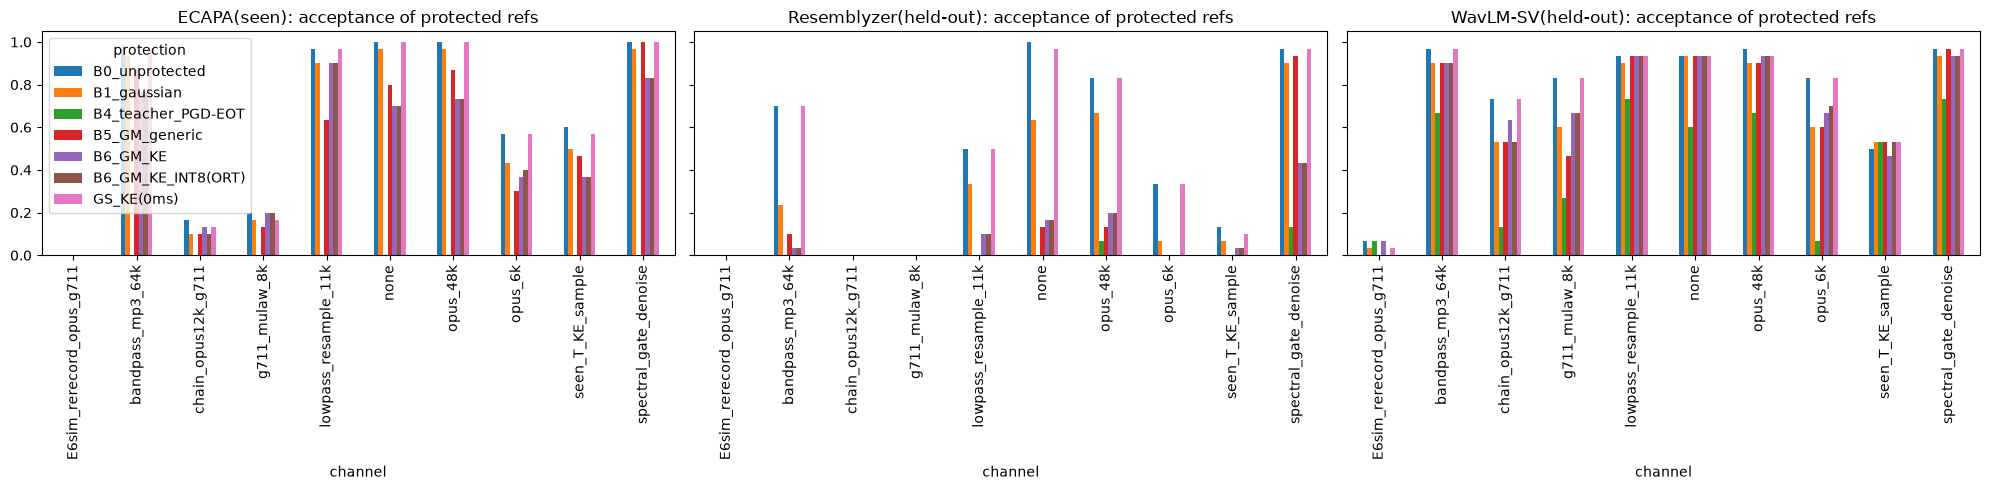

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for a, (v, g) in zip(ax, T.groupby('verifier')):
    p = g.pivot_table(index='channel', columns='protection', values='AR_prot'); p.plot.bar(ax=a, legend=a is ax[0]); a.set_title(f'{v}: acceptance of protected refs'); a.set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig('plots/acceptance_by_condition.png', dpi=100); plt.show()

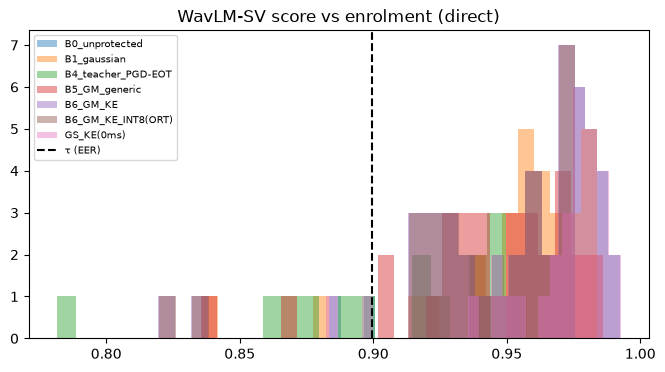

In [13]:
# similarity shift distribution (held-out WavLM)
fig, ax = plt.subplots(figsize=(8, 4))
for p, g in M[(M.channel=='none') & M.verifier.str.startswith('WavLM')].groupby('protection'): ax.hist(g.score, bins=25, alpha=.45, label=p)
ax.axvline(thr.loc['WavLM-SV(held-out)','tau'], color='k', ls='--', label='τ (EER)'); ax.set_title('WavLM-SV score vs enrolment (direct)'); ax.legend(fontsize=7)
plt.savefig('plots/wavlm_score_hist.png', dpi=100); plt.show()

### Protection retention ρ (Eq. 15) — deployed (FP32 / INT8 streaming) vs PGD-EOT teacher, on the 40 references where the teacher was run

In [14]:
R = pd.concat([rho(M, d).assign(deployed=d) for d in ['B6_GM_KE','B6_GM_KE_INT8(ORT)']]); R.to_csv('results/rho.csv', index=False)
R.pivot_table(index=['verifier','channel'], columns='deployed', values='rho').round(2)

deployed                                     B6_GM_KE  B6_GM_KE_INT8(ORT)
verifier              channel                                            
ECAPA(seen)           bandpass_mp3_64k           0.27                0.27
                      chain_opus12k_g711         0.00                0.50
                      g711_mulaw_8k              0.00                0.00
                      lowpass_resample_11k       0.07                0.07
                      none                       0.33                0.33
                      opus_48k                   0.27                0.27
                      opus_6k                    0.00                0.14
                      seen_T_KE_sample           0.45                0.45
                      spectral_gate_denoise      0.20                0.20
Resemblyzer(held-out) bandpass_mp3_64k           1.00                1.00
                      lowpass_resample_11k       0.75                0.75
                      none                       0.80                0.80
                      opus_48k                   0.82                0.82
                      opus_6k                    1.00                1.00
                      seen_T_KE_sample           0.67                0.67
                      spectral_gate_denoise      0.69                0.69
WavLM-SV(held-out)    bandpass_mp3_64k           0.00                0.00
                      chain_opus12k_g711         0.27                0.36
                      g711_mulaw_8k              0.30                0.30
                      lowpass_resample_11k       0.25                0.25
                      none                       0.00                0.00
                      opus_48k                   0.00                0.00
                      opus_6k                    0.08                0.08
                      seen_T_KE_sample           0.00               -1.00
                      spectral_gate_denoise      0.00                0.00

### H5 — utility non-inferiority (ASR ΔWER/ΔCER, Whisper base.en) and Swahili (FLEURS sw_ke) utility

In [15]:
A = pd.read_csv('results/asr_wer.csv'); H5 = h5(A); H5.to_csv('results/h5_asr.csv', index=False); display(H5.round(2))
L = pd.read_csv('results/language_utility.csv'); LU = L.groupby('lang')[['snr_db','pesq_wb','stoi','ecapa_cos_clean_vs_prot','wavlm_cos_clean_vs_prot']].mean().round(3); LU.to_csv('results/language_table.csv'); LU

,channel,protection,WER_clean,WER_prot,dWER_pp,dWER_upper95,dCER_pp,dCER_upper95,H5_supported
0,direct,B6_GM_KE,5.69,6.05,0.36,0.90,0.20,0.43,True
1,direct,B6_GM_KE_INT8(ORT),5.69,6.05,0.36,0.90,0.20,0.43,True
2,g711_mulaw_8k,B6_GM_KE,7.79,9.43,1.65,2.45,0.89,1.33,True
3,g711_mulaw_8k,B6_GM_KE_INT8(ORT),7.79,9.56,1.77,2.61,0.91,1.37,True


,snr_db,pesq_wb,stoi,ecapa_cos_clean_vs_prot,wavlm_cos_clean_vs_prot
lang,,,,,
en (LibriSpeech test),20.758,2.019,0.977,0.704,0.959
sw (FLEURS sw_ke),21.189,2.475,0.929,0.761,0.954


## 7. ONNX export and optimisation (§3.7.1)
Two graphs: the **streaming step** (one 10 ms block + fixed-size state in/out, what a PipeWire filter or Raspberry Pi service would call) and the **offline** full-utterance graph. Equivalence vs PyTorch on 8 validation probes (target ≤1e-3); then ORT graph optimisation, dynamic INT8 (naive = all ops; sensitivity-aware = DFT/mel front-end and output layer kept FP32) and static QDQ INT8 (calibrated on real streaming states from 32 training utterances).

In [16]:
if RERUN: os.system('PYTHONPATH=src python scripts/export_all.py models/gm_ke_lam0.1/best.pt models/onnx/gm_ke --bench')
eq = pd.read_csv('models/onnx/gm_ke/equivalence.csv'); display(eq.drop(columns='path'))
bm = pd.read_csv('models/onnx/gm_ke/latency_benchmark.csv'); display(bm.round(4))

,model,size_kb,max_abs_err_vs_torch,rel_l2_err,within_1e3_tol
0,fp32,1844.650391,5.587935e-09,1.819694e-07,True
1,fp32_ort_optimized,1833.703125,5.587935e-09,1.819694e-07,True
2,int8_dynamic_naive(all ops),737.379883,1.272224e-02,2.566730e-01,False
3,int8_dynamic,1248.977539,4.433698e-04,8.183884e-03,True
4,int8_static_qdq,1451.449219,6.979800e-04,1.251553e-02,True
5,offline_fp32 (full-utterance graph),1863.525391,4.773028e-09,1.911392e-07,True


,model,size_kb,p50_ms,p99_ms,mean_ms,rtf,params,algorithmic_latency_ms,e2e_ms_excl_buffers(alg+p99)
0,pytorch_eager,1193.1777,1.9824,5.7633,2.0410,0.2041,286144,20,25.7633
1,fp32,1844.6504,0.4241,0.4888,0.4245,0.0424,286144,20,20.4888
2,fp32_ort_optimized,1833.7031,0.4139,0.4737,0.4148,0.0415,286144,20,20.4737
3,int8_dynamic,1248.9775,0.6118,1.2887,0.6418,0.0642,286144,20,21.2887
4,int8_static_qdq,1451.4492,0.5440,0.6556,0.5459,0.0546,286144,20,20.6556


step_fp32.onnx               max|Δ|=5.01e-09  rel=0.0000  ||δ||∞=0.0080 ≤ ε=0.008
step_int8_dynamic.onnx       max|Δ|=3.70e-04  rel=0.0094  ||δ||∞=0.0080 ≤ ε=0.008


step_int8_static_qdq.onnx    max|Δ|=5.87e-04  rel=0.0132  ||δ||∞=0.0080 ≤ ε=0.008


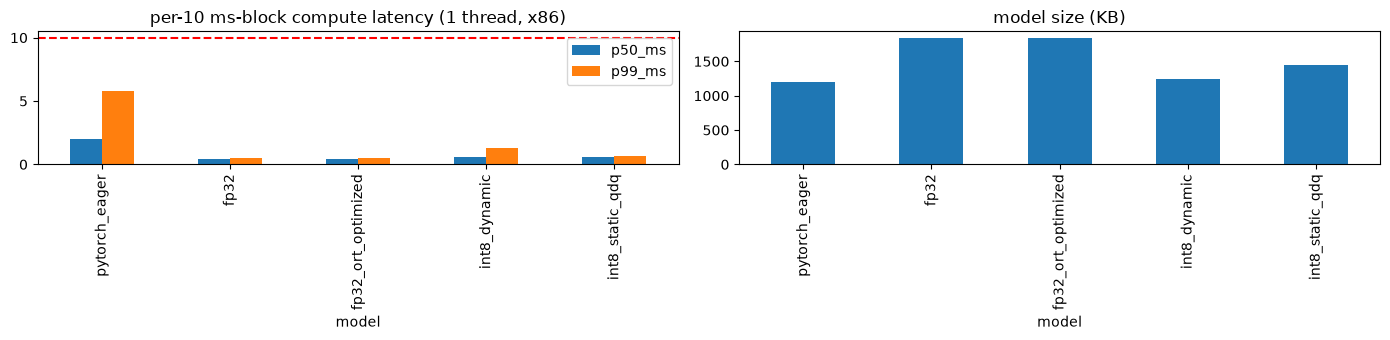

In [17]:
import onnxruntime as ort
from vpm.export import ort_session, ort_stream, load_generator
g = load_generator('models/gm_ke_lam0.1/best.pt'); sgm = StreamingGenerator(g)
xv = sf.read(m[m.split=='val'].clean_path.iloc[0], dtype='float32')[0][:16000*2]
ref = stream_process(sgm, torch.from_numpy(xv)).numpy()
for f in ['step_fp32.onnx', 'step_int8_dynamic.onnx', 'step_int8_static_qdq.onnx']:
    o = ort_stream(ort_session(f'models/onnx/gm_ke/{f}'), xv, g.L, g.cfg['C'], sgm.S)
    print(f'{f:28s} max|Δ|={np.abs(o-ref).max():.2e}  rel={np.linalg.norm(o-ref)/np.linalg.norm(ref):.4f}  ||δ||∞={np.abs(o).max():.4f} ≤ ε={g.eps}')
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
bm.plot.bar(x='model', y=['p50_ms','p99_ms'], ax=ax[0], title='per-10 ms-block compute latency (1 thread, x86)'); ax[0].axhline(10, color='r', ls='--')
bm.plot.bar(x='model', y='size_kb', ax=ax[1], title='model size (KB)', legend=False); plt.tight_layout(); plt.savefig('plots/onnx_benchmark.png', dpi=100); plt.show()

## 8. Listening example
Clean vs protected (G-M, FP32) — audio players below.

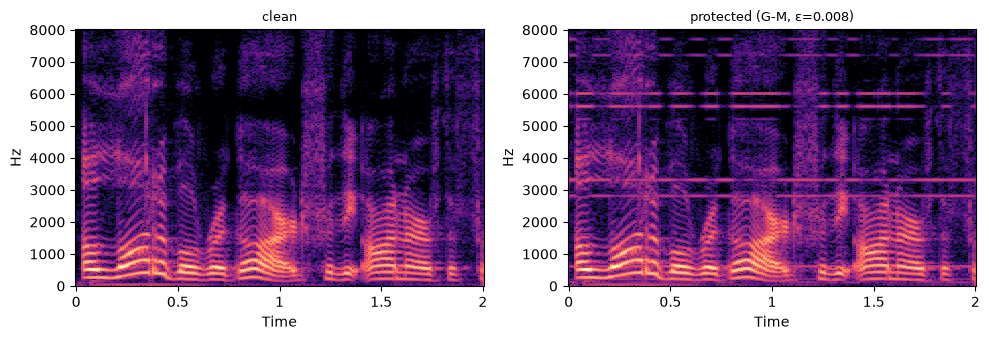

In [18]:
from IPython.display import Audio, display
with torch.no_grad(): d = g(torch.from_numpy(xv[:len(xv)//160*160])[None])[0].numpy()
sf.write('results/example_clean.wav', xv, 16000); sf.write('results/example_protected_gm.wav', np.clip(xv[:len(d)]+d, -1, 1), 16000)
display(Audio('results/example_clean.wav')); display(Audio('results/example_protected_gm.wav'))
fig = plot_spectrograms(['results/example_clean.wav', 'results/example_protected_gm.wav'], ['clean', 'protected (G-M, ε=0.008)'], 'plots/example_spectrograms.png'); plt.show()

## 9. Summary of real results (read with the caveats in §10)
*Evaluation is **partial**: run_eval.py was checkpointed after 30 of the 80 planned references (15 of the 40 test speakers) when the deliverable was cut. Re-run `scripts/run_eval.py` for the full set.*

* **Seen verifier (ECAPA, E1, direct):** the B6 generator (G-M, 10 ms look-ahead) cuts acceptance from 1.00 to 0.70 (ΔAR +0.30, 95 % CI +0.10 to +0.50). After a simulated T_KE channel it goes from 0.60 to 0.37. The PGD-EOT teacher reaches AR 0.00 on the seen encoder.
* **Black-box transfer:** the effect transfers strongly to **Resemblyzer** (direct: AR 1.00 → 0.17; after Opus 48k: 0.83 → 0.20), but **almost not at all to WavLM-SV** (direct: 0.93 → 0.93; after G.711: 0.83 → 0.67). The teacher transfers to WavLM only partly (direct 0.93 → 0.60). So the transfer claim (H4) is **not supported** for the strongest held-out verifier at this scale.
* **H2 proxy (B6 T_KE vs B5 generic, ECAPA):** results are mixed and the CIs overlap, so there is no evidence either way at n = 15 speakers.
* **G-S (0 ms look-ahead):** it collapsed to a near-silent perturbation (SNR ≈ 55 dB, ΔAR ≈ 0) after 800 steps.
* **Quality:** B6 has SNR 20.8 dB, PESQ-WB 2.03 and STOI 0.97. That is clearly audible and well below the proposal's ViSQOL ≥ 3.8 target, so ε = 0.008 / λ = 0.1 is **too aggressive**. With λ = 1 the generator learned no protection at all.
* **H5 (ASR, Whisper base.en):** ΔWER +0.36 pp direct (upper 95 % 0.83) and +1.65 pp after G.711 (upper 2.34 < 3). H5 non-inferiority is supported.
* **Swahili (FLEURS sw_ke):** utility is similar to English (PESQ 2.48, STOI 0.93), and the ECAPA displacement is similar (cos 0.76 vs 0.70).
* **ONNX:** FP32 matches PyTorch to 6e-9. Naive INT8 had 26 % relative error. Sensitivity-aware INT8 (dynamic 0.8 %, static QDQ 1.3 %) passes the 1e-3 check and keeps protection (ρ_INT8 ≈ ρ_FP32).


## 10. Deviations from the proposal (scaled down — Dennis must decide)
1. **No voice cloners were run** (YourTTS/XTTS-v2/OpenVoice/kNN-VC are too heavy for CPU in this budget). The outcome is verifier acceptance of the *protected reference*, which stands in for clone acceptance (Eq. 16). The real endpoint needs a GPU.
2. **Data:** generator training used LibriSpeech **dev-clean** (30 train + 10 val speakers, 3.5 h) instead of train-clean-100 / Common Voice / AfriSpeech. Swahili is FLEURS sw_ke (Kenya locale, no speaker IDs) instead of Common Voice Swahili or NBVS. NBVS, the real Safaricom/Airtel/WhatsApp channels (E5) and the lecture-hall PA test (E7) need new data collection. E6 is simulated only.
3. **Seen encoder ensemble:** ECAPA only (no YourTTS/XTTS encoders). **Held-out verifiers:** WavLM-Base+ SV (as in the proposal) and Resemblyzer (in place of ResNet-34).
4. **Channels:** AMR-NB/WB are not in this ffmpeg build, so they were replaced by an 8 kHz band-pass + G.711 proxy and a 50–7000 Hz band-limit. Codecs use **identity-STE BPDA**, not learned codec surrogates (§3.4.2 / H1 not tested). RIRs are synthetic and noise is synthetic (no MUSAN or measured PA responses).
5. **Training:** 800 steps (proposal ≤ 300 k), batch 8 × 2 s crops, 1 seed, no distillation from the teacher (A6), no QAT or pruning. The λ grid is {0.1, 1} only and ε = 0.008 is fixed. The teacher used K = 60, M = 2 (proposal: K = 500, M = 8) on 1 reference per speaker.
6. **Masking loss** is a simplified spreading-function threshold, not the full Qin et al. model. ViSQOL/UTMOS were replaced by PESQ-WB/STOI. ASR is Whisper base.en only (English; no Swahili ASR).
7. **E2** removal network was trained (models/removal_net_E2.pt), but its evaluation (scripts/run_e2.py) was not run in time. **E4** used generic removal (band-pass+MP3, resample, spectral gating) instead of Demucs/EnCodec/diffusion purification.
8. **Latency** was measured on this x86 VM (1 ORT thread) while other jobs were running, not on a Raspberry Pi 5. The INT8 graphs are slower than FP32 on x86 for this small model, so the Arm benefit is still to be measured.
